do time series of land vs ocean of 
- C
- SSHF
- SLHF
- Theta pert
- MSE (BL??)

In [1]:
import wrf
from wrf import CoordPair, vertcross, get_cartopy, getvar, latlon_coords, to_np, destagger, ll_to_xy
import numpy as np
from netCDF4 import Dataset 
import matplotlib.pyplot as plt
import pyart
import geocat.viz as gv
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter
import os
import glob
from metpy.units import units
import cartopy.crs as crs
import pandas as pd
import xarray as xr
import metpy 
import metpy.calc as mpcalc
from matplotlib.dates import DateFormatter
from metpy.calc import moist_static_energy, dry_static_energy, relative_humidity_from_mixing_ratio
from metpy.interpolate import cross_section
import pkg_resources


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
# Set directory where wrfout files reside, and list the files for processing.  Set up for a directory with only wrfout files.
os.chdir("/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1/")
print(os.getcwd())
datafiles = (sorted(glob.glob("wrfout_d03*")))#17_00:00:00")))
numfiles=len(datafiles)
print(numfiles)
print(datafiles[23])
# Set up for saving graphics files
plotsdir = '/glade/u/home/athornton/wrf_visualization/cold_pool_data/'

/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1
85
wrfout_d03_2018-08-25_17:30:00


In [3]:
input = "wrfout_d03_2018-08-25_23:30:00" 
ncfile = Dataset(input)
slp = getvar(ncfile, "slp")
lats, lons = latlon_coords(slp)
lats_np = to_np(lats)
lons_np = to_np(lons)

In [4]:
def mass_weighted_vert_integral(height, data):
    # data is expected to be on pressure levels
    levels = z.bottom_top
    deltaZ = (levels - levels.shift(bottom_top=1))
    vert_int_data = ((data.shift(bottom_top=1)+data)*.5*deltaZ).sum(dim='bottom_top') / metpy.constants.earth_gravity    
    return  vert_int_data

In [7]:
## Northern MCS
# latmin = 11.5
# latmax = 14.
# lonmin = -18.
# lonmax = -12.

## Southern MCS
latmin = 8.5
latmax = 10.25
lonmin = -16.5
lonmax = -10.75

## Oceanic MCS
# latmin = 5.
# latmax = 10.
# lonmin = -20.
# lonmax = -18.

lats = [latmin, latmax]
lons = [lonmin, lonmax]
# From Anantha...
# Simple linear interpolation between each latitude point
def get_lats():
    new_lats = []
    for i in range(0,len(lats)):
        if lats[i] == lats[-1]:
            new_lats.append(lats[i])
        else:
            next_value = 0.5*(lats[i] + lats[i+1])
            new_lats.append(lats[i])
            new_lats.append(next_value)
    return new_lats
# From Anantha...
# Simple linear interpolation between each latitude point
def get_lons():
    new_lons = []
    for i in range(0,len(lons)):
        if lons[i] == lons[-1]:
            new_lons.append(lons[i])
        else:
            next_value = 0.5*(lons[i] + lons[i+1])
            new_lons.append(lons[i])
            new_lons.append(next_value)
    return new_lons

new_lats = get_lats()
lats = new_lats
new_lons = get_lons()
lons = new_lons
new_lats = get_lats()
print(new_lats)
new_lons = get_lons()
print(new_lons)

[8.5, 8.9375, 9.375, 9.8125, 10.25]
[-16.5, -15.0625, -13.625, -12.1875, -10.75]


In [6]:
lat = lats_np[:,0]
lon = lons_np[0,:]

In [45]:
ocean_lat = new_lats[0] # 0 for north, 1 for south MCS
ocean_lon = new_lons[0] # 0 for north, 1 for south
idx = np.where(lat <= ocean_lat)
ocean_lat_idx = idx[0][-1]
idx = np.where(lon <= ocean_lon)
ocean_lon_idx = idx[0][-1]

coast_lat = new_lats[1] # 1 for north, 2 for south
coast_lon = new_lons[1] # 1 for north, 2 for south
idx = np.where(lat <= coast_lat)
coast_lat_idx = idx[0][-1]
idx = np.where(lon <= coast_lon)
coast_lon_idx = idx[0][-1]

land_lat = new_lats[2] # 2 for north, 3 for south
land_lon = new_lons[2] # 2 for north, 3 for south
idx = np.where(lat <= land_lat)
land_lat_idx = idx[0][-1]
idx = np.where(lon <= land_lon)
land_lon_idx = idx[0][-1]

In [46]:
times = []
temp_ocean = []
lhf_ocean = []
shf_ocean = []

temp_coast = []
lhf_coast = []
shf_coast = []

temp_land = []
lhf_land = []
shf_land = []
for i in range(0,numfiles):
    wrf_out_data = xr.open_dataset(datafiles[i])  
    ncfile = Dataset(datafiles[i])
    Time=wrf.extract_times(ncfile, timeidx=0, method='cat', squeeze=True, cache=None, meta=False, do_xtime=False)
    timestr=(str(Time))
    times.append(timestr)
    # Set up one time string for plot titles, another for file names
    titletime=(timestr[0:10]+' '+timestr[11:16])
    filetime=(timestr[0:10]+'_'+timestr[11:16])
    print('WRF valid time: ',filetime)

    lhf = wrf_out_data['LH'][0].metpy.quantify()
    shf = wrf_out_data['HFX'][0].metpy.quantify()
    #qf = wrf_out_data['QFX'][0].metpy.quantify()
    theta_pert = wrf_out_data['T'][0].metpy.quantify()
    # rain = wrf_out_data['RAINNC'][0].metpy.quantify()
    t2 = wrf_out_data['T2'][0].metpy.quantify()
    t2 = t2.metpy.convert_units('degC')


    ####### OCEAN1
    sn_ocean = t2.south_north[ocean_lat_idx]
    we_ocean = t2.west_east[ocean_lon_idx]
    
    temp2 = t2.sel(south_north=sn_ocean, west_east=we_ocean)
    shfx = shf.sel(south_north=sn_ocean, west_east=we_ocean)
    lhfx = lhf.sel(south_north=sn_ocean, west_east=we_ocean)

    lhf_ocean.append(lhfx)
    shf_ocean.append(shfx)
    temp_ocean.append(temp2)

    ######### COAST
    sn_coast = t2.south_north[coast_lat_idx]
    we_coast = t2.west_east[coast_lon_idx]

    temp2 = t2.sel(south_north=sn_coast, west_east=we_coast)
    shfx = shf.sel(south_north=sn_coast, west_east=we_coast)
    lhfx = lhf.sel(south_north=sn_coast, west_east=we_coast)

    lhf_coast.append(lhfx)
    shf_coast.append(shfx)
    temp_coast.append(temp2)

    ######## LAND1
    sn_land = t2.south_north[land_lat_idx]
    we_land = t2.west_east[land_lon_idx]
    
    temp2 = t2.sel(south_north=sn_land, west_east=we_land)
    shfx = shf.sel(south_north=sn_land, west_east=we_land)
    lhfx = lhf.sel(south_north=sn_land, west_east=we_land)

    lhf_land.append(lhfx)
    shf_land.append(shfx)
    temp_land.append(temp2)



WRF valid time:  2018-08-25_06:00
WRF valid time:  2018-08-25_06:30
WRF valid time:  2018-08-25_07:00
WRF valid time:  2018-08-25_07:30
WRF valid time:  2018-08-25_08:00
WRF valid time:  2018-08-25_08:30
WRF valid time:  2018-08-25_09:00
WRF valid time:  2018-08-25_09:30
WRF valid time:  2018-08-25_10:00
WRF valid time:  2018-08-25_10:30
WRF valid time:  2018-08-25_11:00
WRF valid time:  2018-08-25_11:30
WRF valid time:  2018-08-25_12:00
WRF valid time:  2018-08-25_12:30
WRF valid time:  2018-08-25_13:00
WRF valid time:  2018-08-25_13:30
WRF valid time:  2018-08-25_14:00
WRF valid time:  2018-08-25_14:30
WRF valid time:  2018-08-25_15:00
WRF valid time:  2018-08-25_15:30
WRF valid time:  2018-08-25_16:00
WRF valid time:  2018-08-25_16:30
WRF valid time:  2018-08-25_17:00
WRF valid time:  2018-08-25_17:30
WRF valid time:  2018-08-25_18:00
WRF valid time:  2018-08-25_18:30
WRF valid time:  2018-08-25_19:00
WRF valid time:  2018-08-25_19:30
WRF valid time:  2018-08-25_20:00
WRF valid time

In [47]:
# open all wrfout files for this ensemble member
data = xr.open_mfdataset(datafiles, concat_dim='Time', combine='nested', engine='netcdf4')
rain = data.RAINNC.compute()
time = data.XTIME.compute()
rain_list = [np.zeros_like(rain[0])]  # Start with a zero array for the first time step

for i in range(1, len(rain)):
    rain_hour = rain[i] - rain[i-1] # subtract computed accumulated rain note from previous timestep
    rain_hour = np.maximum(rain_hour, 0)  # Set negative values to 0
    rain_list.append(rain_hour)

rain = xr.DataArray(rain_list)

In [48]:
rain_ocean = rain.sel(dim_1=sn_ocean, dim_2=we_ocean)
rain_coast = rain.sel(dim_1=sn_coast, dim_2=we_coast)
rain_land = rain.sel(dim_1=sn_land, dim_2=we_land)

In [49]:
times_pd = pd.to_datetime(times)
xlim = pd.date_range(times_pd[0], times_pd[-1], freq='2h')

In [50]:
temp = [temp_land, temp_coast, temp_ocean]
rain = [rain_land, rain_coast, rain_ocean]
lhf = [lhf_land, lhf_coast, lhf_ocean]
shf = [shf_land, shf_coast, shf_ocean]

In [51]:
#titles = ['Land', 'Coast', 'Ocean']
titles = ['3', '2', '1']
lat_loc = [land_lat, coast_lat, ocean_lat]
lon_loc = [land_lon, coast_lon, ocean_lon]

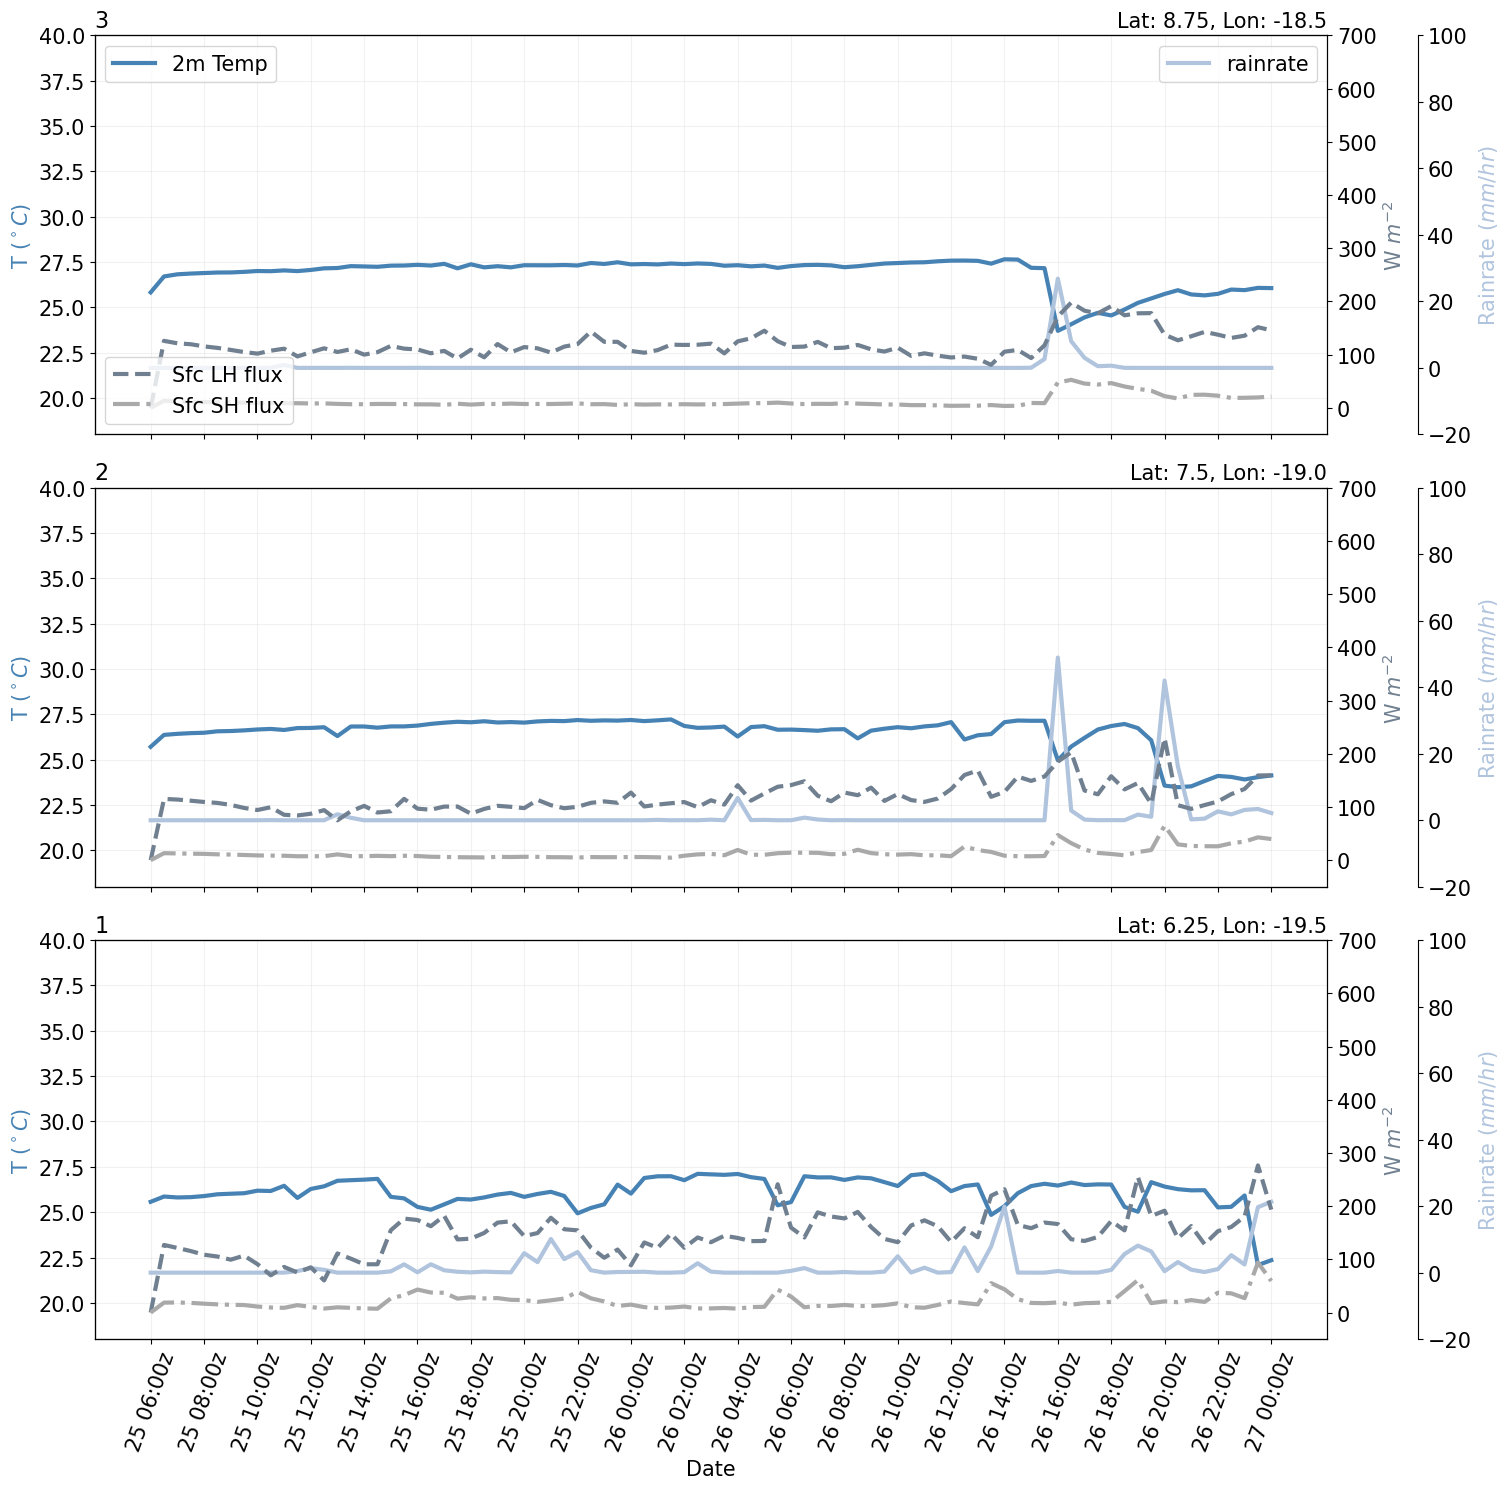

In [52]:
plt.rcParams['savefig.dpi'] = 255

fig, ax = plt.subplots(3,figsize=(15,15), constrained_layout=True)
#ax.set_title('Cold pool passage', size=15, weight='bold',loc='left')

for i in range(0,3):
    ax[i].set_title('Lat: '+str(lat_loc[i])+', Lon: '+str(lon_loc[i]), size=15,loc='right')
    ax[i].set_title(titles[i], size=16,loc='left')
    ax[i].set_xticklabels([])
    ax[i].plot(times_pd, temp[i], color='steelblue', linestyle='solid', label='2m Temp', linewidth=3.)
    ax[i].set_ylabel('T ($^\circ$$C$)', size=15, color='steelblue')
    ax[i].set_ylim(18,40)
    
    ax3 = ax[i].twinx()
    ax2 = ax[i].twinx()
    
    ax2.plot(times_pd, lhf[i], color='slategray', label='Sfc LH flux', linestyle='--', linewidth=3.)
    ax2.plot(times_pd, shf[i], color='darkgray', label='Sfc SH flux', linestyle='-.', linewidth=3.)
    ax2.set_ylim(-50,700)
    ax2.set_ylabel('W $m^{-2}$', size=15, color='slategray')
    
    ax3.plot(times_pd, rain[i]*2, color='lightsteelblue', label='rainrate', linewidth=3.) # divide by two to get mm/hr instead of mm/30 mins
    ax3.set_ylabel('Rainrate ($mm/hr$)', size=15, color='lightsteelblue')
    ax3.set_ylim(-20,100)
    ax3.spines['right'].set_position(('outward', 65))
    
    
    ax[i].grid(color='lightgray',alpha=0.3)
    ax[i].tick_params(axis="both", which="major", labelsize=15)
    ax2.tick_params(axis="both", which="major", labelsize=15)
    ax3.tick_params(axis="both", which="major", labelsize=15)
    ax[i].set_xticks(xlim)

    if i == 0:
        ax[i].legend(loc='upper left', fontsize=15)
        ax2.legend(loc="lower left", fontsize=15)
        ax3.legend(loc="upper right", fontsize=15)


ax[2].set_xlabel('Date', size=15)
date_form = DateFormatter('%d %H:%Mz')
#matplotlib.dates.HourLocator(byhour=None, interval=1, tz=None)
ax[2].xaxis.set_major_formatter(date_form)
#ax[2].set_xticks(xlim)
ax[2].tick_params(axis='x', rotation=70)
plt.tight_layout()
plt.savefig(plotsdir+'timeseries_oceanic.png')


In [ ]:
## Try once more with slightly shifted coast point
latmin = 8.5
latmax = 10.25
lonmin = -16.5
lonmax = -10.75
# if issue persists, slightly shift ocean point northward

In [7]:
coast_lat

12.75

In [8]:
coast_lon

-15.0

In [9]:
wrf_out_data = xr.open_dataset(datafiles[0])

In [17]:
land = wrf_out_data['LANDMASK']

In [29]:
sn_coast = land.south_north[coast_lat_idx]
we_coast = land.west_east[coast_lon_idx]

temp2 = land.sel(south_north=sn_coast, west_east=we_coast)

In [31]:
temp2.values

array([1.], dtype=float32)

In [23]:
land.south_north[coast_lat_idx]

<xarray.DataArray 'south_north' ()> Size: 8B
array(1303)